In [2]:
from matplotlib import pyplot as plt
import scipy
import numpy as np
from scipy import sparse
import sys
sys.path.insert(0, '../..')   # goes from paper_plots/fig_1_compQITE -> repo root
from modules import Hamiltonian as ham
from modules import PauliStrings
from modules import Evolution as evol
from matplotlib.lines import Line2D

In [3]:
color1="#0041FC"
color2="#FC9904"
color3="#7D7548"

In [4]:
def fidelity_pure(psi,phi):
    '''
    input values should be column vectors
    '''
    F=np.abs(psi.conj().T@phi)**2
    return F

In [5]:
HeiQITE = np.load("heisenberg/qite_default/trajectory.npz", allow_pickle=True)
ordQITE = np.load("tfim_ord/qite_default/trajectory.npz", allow_pickle=True)
disQITE = np.load("tfim_disord/qite_default/trajectory.npz", allow_pickle=True)

HeiSpQ = np.load("heisenberg/spqite/trajectory.npz", allow_pickle=True)
ordSpQ = np.load("tfim_ord/spqite/trajectory.npz", allow_pickle=True)
disSpQ = np.load("tfim_disord/spqite/trajectory.npz", allow_pickle=True)

In [4]:
N = 100
Ns=np.arange(0,N)
NQ_Hei=np.count_nonzero(HeiQITE["a"][1])
NQ_ord=np.count_nonzero(ordQITE["a"][1])
NQ_dis=np.count_nonzero(disQITE["a"][1])

frac_Hei = np.zeros(N)
frac_ord = np.zeros(N)
frac_dis = np.zeros(N)

for i in range(N):
    frac_Hei[i] = np.count_nonzero(HeiSpQ["a"][i]) / NQ_Hei
    frac_ord[i] = np.count_nonzero(ordSpQ["a"][i]) / NQ_ord
    frac_dis[i] = np.count_nonzero(disSpQ["a"][i]) / NQ_dis

In [45]:
print(NQ_Hei, NQ_ord, NQ_dis)
print(frac_ord[-1])

7936 16128 960
0.019097222222222224


In [5]:
psiHeiQITE = sparse.load_npz("heisenberg/qite_default/states.npz").toarray()
psiordQITE = sparse.load_npz("tfim_ord/qite_default/states.npz").toarray()
psidisQITE = sparse.load_npz("tfim_disord/qite_default/states.npz").toarray()

psiHeiSpQ = sparse.load_npz("heisenberg/spqite/states.npz").toarray()
psiordSpQ = sparse.load_npz("tfim_ord/spqite/states.npz").toarray()
psidisSpQ = sparse.load_npz("tfim_disord/spqite/states.npz").toarray()

In [ ]:
n_qubits = 8
D=4
psi0np=np.zeros((2**n_qubits,1),dtype=complex)
psi0np[0]=1
psi_0=sparse.csc_matrix(psi0np/np.linalg.norm(psi0np))
NQ=100
dt=0.05
H, H_trot = ham.TFIM(0.5,1,n_qubits)
E,V = np.linalg.eig(H.toarray())
GS_dis = V[0,:]

EQ_lasso,statedisSpQ,a_lasso = evol.QITE(n_qubits,H,H_trot,D,psi_0,NQ,dt,method='vanilla_lasso')

In [17]:
H_Hei, Htrot = ham.Heisenberg_PBC(1,8,2,False)
E_Hei,V_Hei = np.linalg.eigh(H_Hei)
GS_Hei = V_Hei[:,0]
print(np.real(E_Hei)[0])
H_ord, Htrot = ham.TFIM(1,0.5,8,2,False)
E_ord,V_ord = np.linalg.eigh(H_ord)
GS_ord = V_ord[:,0]
print(E_ord[0])
H_dis, Htrot = ham.TFIM(0.5,1,8,2,False)
E_dis,V_dis = np.linalg.eigh(H_dis)
GS_dis = V_dis[:,0]
print(E_dis[0])


Heisenberg model with PBC and Hamiltonian pieces of locality T=2
Succesfull Troterization
The Trotterization consists of 8 terms with the starting qubit of each piece at [0, 1, 2, 3, 4, 5, 6, 7]
-14.604373635748706
-8.50908223514028
-8.509082235140282


In [27]:
F_Q_Hei = np.zeros(N)
F_Sp_Hei = np.zeros(N)
F_Q_ord = np.zeros(N)
F_Sp_ord = np.zeros(N)
F_Q_dis = np.zeros(N)
F_Sp_dis = np.zeros(N)


for i in range(N):
    F_Q_Hei[i]  = fidelity_pure(GS_Hei,psiHeiQITE[:,i])
    F_Sp_Hei[i] = fidelity_pure(GS_Hei,psiHeiSpQ[:,i])
    F_Q_ord[i]  = fidelity_pure(GS_ord,psiordQITE[:,i])
    F_Sp_ord[i] = fidelity_pure(GS_ord,psiordSpQ[:,i])
    F_Q_dis[i]  = fidelity_pure(GS_dis,psidisQITE[:,i])
    F_Sp_dis[i] = fidelity_pure(GS_dis,psidisSpQ[:,i])

dt=0.05
im_tau = np.arange(0,N)*dt

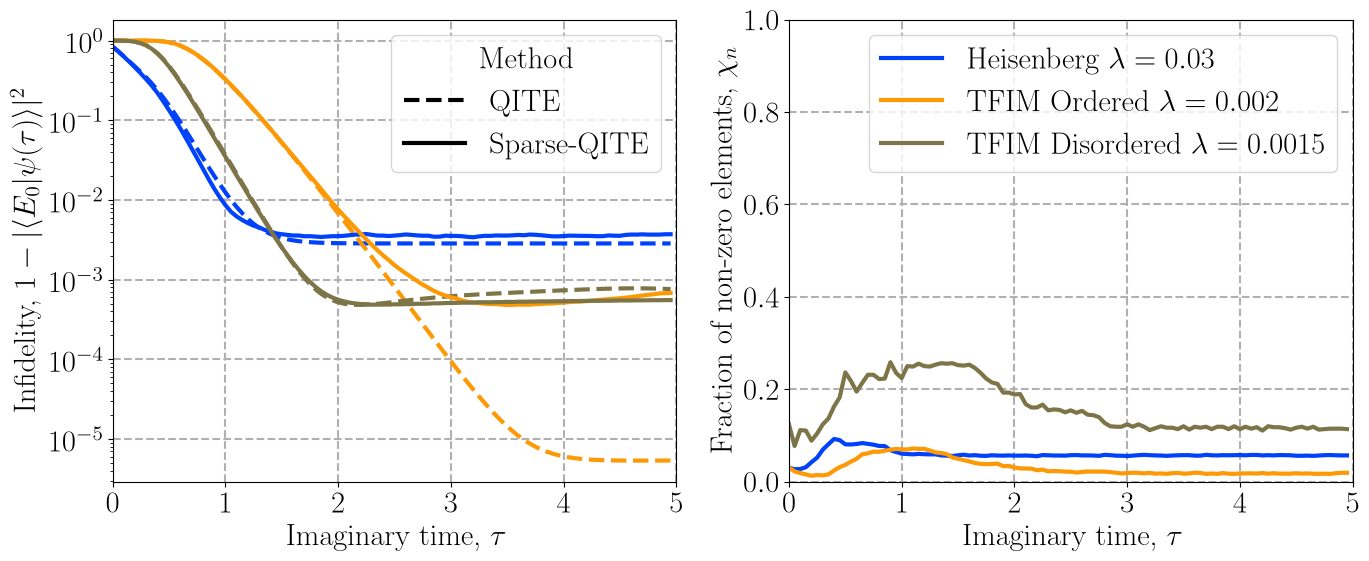

In [39]:
plt.figure(figsize=(16, 6))
plt.rcParams.update({
    "text.usetex": True,
})
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 22}

plt.rc('font', **font)

plt.subplot(1,2,1)
plt.semilogy(im_tau,1-F_Q_Hei,'--',color=color1,linewidth=3,label='Heisenberg $\\lambda = 0.03$')
plt.semilogy(im_tau,1-F_Q_ord,'--',color=color2,linewidth=3,label='Ordered $\\lambda = 0.002$')
plt.semilogy(im_tau,1-F_Q_dis,'--',color=color3,linewidth=3,label='Disordered $\\lambda = 0.0015$')
plt.semilogy(im_tau,1-F_Sp_Hei,'-',color=color1,linewidth=3,label='Heisenberg $\\lambda = 0.03$')
plt.semilogy(im_tau,1-F_Sp_ord,'-',color=color2,linewidth=3,label='Ordered $\\lambda = 0.002$')
plt.semilogy(im_tau,1-F_Sp_dis,'-',color=color3,linewidth=3,label='Disordered $\\lambda = 0.0015$')

legend_items = [
    Line2D([0], [0],  lw=3, linestyle="--",color='black',  label="QITE"),
    Line2D([0], [0],  lw=3, linestyle="-",color='black', label="Sparse-QITE"),
]

plt.legend(handles=legend_items, title="Method")

plt.xlim(0,5)
plt.xlabel("Imaginary time, $\\tau$")
plt.ylabel("Infidelity, $1-|\\langle E_0 | \\psi(\\tau) \\rangle|^2$")
plt.grid(linestyle = '--', linewidth = 1.5)

plt.subplot(1,2,2)
plt.plot(im_tau,frac_Hei,'-',color=color1,linewidth=3,label='Heisenberg $\\lambda = 0.03$')
plt.plot(im_tau,frac_ord,'-',color=color2,linewidth=3,label='TFIM Ordered $\\lambda = 0.002$')
plt.plot(im_tau,frac_dis,'-',color=color3,linewidth=3,label='TFIM Disordered $\\lambda = 0.0015$')

plt.xlabel("Imaginary time, $\\tau$")
plt.ylabel("Fraction of non-zero elements, $\\chi_n$")
plt.ylim(0,1)
plt.xlim(0,5)
plt.legend()
plt.grid(linestyle = '--', linewidth = 1.5)

plt.savefig("QITE_vs_SpQITE.pdf", bbox_inches='tight', dpi=300)